# Benchmarks

How long CtreeX takes for decision trees of increasing size
(synthetic data with 8 numerical and 4 categorical features, three classes).
This notebook is not run by CI;
run it with `uv sync --group notebooks && uv run jupyter lab notebooks/`.
The timings depend on the machine.

In [1]:
import time

import numpy as np
from sklearn.tree import DecisionTreeClassifier

import ctreex
from ctreex import TreeCounterfactualExplainer

SIZES = [100, 500, 1000, 2000, 5000]   # numbers of leaves
REPEATS = 10                           # data points per explanation

rng = np.random.RandomState(0)
n = 20000
numerical = rng.uniform(0, 100, (n, 8))
categorical = [np.eye(5)[rng.randint(0, 5, n)] for _ in range(4)]
X = np.column_stack([numerical] + categorical)
score = (np.sin(numerical[:, 0] / 10) + numerical[:, 1] / 50 - numerical[:, 2] / 70
         + categorical[0][:, 1] - categorical[1][:, 2] + rng.normal(0, .5, n))
y = np.where(score > 0.5, 'a', np.where(score > -0.2, 'b', 'c'))
columns = ['x{}'.format(i) for i in range(8)] + ['c{}_{}'.format(j, k) for j in range(4) for k in range(5)]
print('ctreex', ctreex.__version__, '|', X.shape[0], 'data points,', len(columns), 'columns')

ctreex 0.1.2 | 20000 data points, 28 columns


In [2]:
def timed(function, repeats=1):
    """The average duration of a function in seconds."""
    start = time.perf_counter()
    for _ in range(repeats):
        function()
    return (time.perf_counter() - start) / repeats


timings = {}
for size in SIZES:
    clf = DecisionTreeClassifier(max_leaf_nodes=size, random_state=0).fit(X, y)
    row = {'depth': clf.get_depth()}
    row['explainer'] = timed(lambda: TreeCounterfactualExplainer(clf, columns))
    explainer = TreeCounterfactualExplainer(clf, columns)
    points = iter(X[:REPEATS])
    row['explain_instance'] = timed(lambda: explainer.explain_instance(next(points)), REPEATS)
    row['leaf_distance_matrix'] = timed(explainer.leaf_distance_matrix)
    leaf = int(explainer.leaf_meta_features.leaf_ids[0])
    row['volatility_index'] = timed(lambda: explainer.volatility_index(leaf))
    points = iter(X[:REPEATS])
    row['supportive_explanations'] = timed(lambda: explainer.supportive_explanations(next(points)), REPEATS)
    points = iter(X[:REPEATS])
    row['invariance_ranges'] = timed(lambda: explainer.invariance_ranges(next(points)), REPEATS)
    explanation = explainer.explain_instance(X[0], max_distance=2)
    row['contextualise'] = timed(lambda: explainer.contextualise(explanation))
    row['monotonicity_violations'] = timed(lambda: explainer.monotonicity_violations('x1', positive='a'))
    row['global_summary'] = timed(explainer.global_summary)
    row['feature_audit'] = timed(lambda: explainer.feature_audit('x0'))
    row['flips'] = len(explainer.feature_audit('x0').flips)
    explainer.spec.fit_ranges(X)
    counterfactual = explanation.ranked()[0][1]
    row['sample_counterfactual'] = timed(
        lambda: explainer.sample_counterfactual(X[0], counterfactual, n=100, random_state=0))
    timings[size] = row
    print('{:5d} leaves (depth {:2d}) done'.format(size, row['depth']))

  100 leaves (depth 10) done


  500 leaves (depth 17) done


 1000 leaves (depth 21) done


 2000 leaves (depth 23) done


 5000 leaves (depth 28) done


Seconds per call for:
- explanations of a data point: the average over `REPEATS` data points;
- `contextualise`: all the counterfactuals at distances 1 and 2 of one data point; and
- `sample_counterfactual`: 100 data points.

In [3]:
OPERATIONS = ['explainer', 'explain_instance', 'leaf_distance_matrix', 'volatility_index',
              'supportive_explanations', 'invariance_ranges', 'contextualise',
              'monotonicity_violations', 'global_summary', 'feature_audit',
              'sample_counterfactual']
print('{:24s}'.format('leaves (depth)') + ''.join('{:>12s}'.format('{} ({})'.format(s, timings[s]['depth']))
                                              for s in SIZES))
for operation in OPERATIONS:
    print('{:24s}'.format(operation) + ''.join('{:12.4f}'.format(timings[s][operation]) for s in SIZES))
print('{:24s}'.format('(feature_audit flips)') + ''.join('{:12d}'.format(timings[s]['flips']) for s in SIZES))

leaves (depth)              100 (10)    500 (17)   1000 (21)   2000 (23)   5000 (28)
explainer                     0.0028      0.0208      0.0581      0.1883      0.4395
explain_instance              0.0018      0.0190      0.0509      0.1562      0.3837
leaf_distance_matrix          0.0013      0.0058      0.0278      0.1441      0.5265
volatility_index              0.0001      0.0002      0.0005      0.0015      0.0059
supportive_explanations       0.0003      0.0058      0.0094      0.0181      0.0347
invariance_ranges             0.0003      0.0012      0.0032      0.0112      0.0312
contextualise                 0.0031      0.0339      0.1099      0.4414      1.3382
monotonicity_violations       0.0032      0.0591      0.2752      1.0994      2.9308
global_summary                0.0110      0.1523      0.4885      2.6779     10.9567
feature_audit                 0.0066      0.3906      1.7483      6.5820     19.3241
sample_counterfactual         0.0021      0.0029      0.0047     

`feature_audit` without data lists every pair of leaves where the feature alone changes the prediction,
so its cost grows with the size of its output (the number of flips).

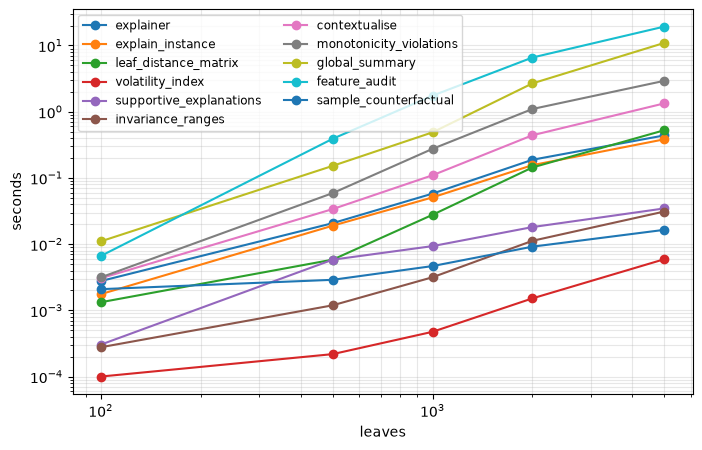

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
for operation in OPERATIONS:
    ax.plot(SIZES, [timings[s][operation] for s in SIZES], marker='o', label=operation)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('leaves')
ax.set_ylabel('seconds')
ax.legend(fontsize='small', ncol=2)
ax.grid(True, which='both', alpha=0.3);

## Tree ensembles (experimental)

Seconds per explanation of a random forest (depth 5) at distance 1 and at distances 1 and 2,
with the number of cells between the thresholds of all its trees;
the number of points evaluated at distance 2 grows with the square of the number of cells.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from ctreex.ensemble import EnsembleCounterfactualExplainer

FORESTS = [10, 20, 50, 100]   # numbers of trees
print('{:>6s}{:>8s}{:>14s}{:>14s}'.format('trees', 'cells', 'distance 1', 'distance 2'))
for size in FORESTS:
    forest = RandomForestClassifier(n_estimators=size, max_depth=5, random_state=0).fit(X[:5000], y[:5000])
    forest_explainer = EnsembleCounterfactualExplainer(forest, columns, max_evaluations=10 ** 8)
    first = timed(lambda: forest_explainer.explain_instance(X[0], max_distance=1))
    second = timed(lambda: forest_explainer.explain_instance(X[0]))
    print('{:6d}{:8d}{:14.3f}{:14.3f}'.format(size, len(forest_explainer.meta_features), first, second))

 trees   cells    distance 1    distance 2
    10     209         0.002         0.066


    20     405         0.004         0.265


    50     957         0.011         2.524


   100    1897         0.029        17.303
